In [266]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load cleaned Nike dataset

df = pd.read_csv("Nike_Sales_With_Costs.csv")

# Display first 5 rows

display(df.head())

,Order_ID,Gender_Category,Product_Line,Product_Name,Size,Units_Sold,MRP,Discount_Applied,Revenue,Order_Date,Sales_Channel,Region,Profit,Production_Cost,Transportation_Cost,Online_Shipment
0,2007,Kids,Training,SuperRep Go,M,1.0,NaN,0.32,0.00,NaN,Retail,Bangalore,2928.36,NaN,NaN,0.0
1,2016,Women,Basketball,Air Jordan,M,1.0,9871.75,0.30,6910.22,NaN,Retail,hyderbad,2452.69,4442.29,296.15,0.0
2,2026,Kids,Lifestyle,Blazer Mid,XL,1.0,NaN,0.16,0.00,2024-08-10,Retail,Kolkata,2301.64,NaN,NaN,0.0
3,2031,Men,Soccer,Premier III,NaN,4.0,3493.04,0.82,2514.99,2024-05-09,Online,Delhi,350.70,6287.47,419.16,80.0
4,2035,Kids,Basketball,Zoom Freak,NaN,4.0,NaN,0.38,0.00,17-11-2024,Online,Bangalore,2914.83,NaN,NaN,80.0


In [267]:
# Check dataset dimensions

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Check column names and data types

print("\nDataset information:")
df.info()

Number of rows: 229
Number of columns: 16

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 229 entries, 0 to 228
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             229 non-null    int64  
 1   Gender_Category      229 non-null    object 
 2   Product_Line         229 non-null    object 
 3   Product_Name         229 non-null    object 
 4   Size                 177 non-null    object 
 5   Units_Sold           229 non-null    float64
 6   MRP                  110 non-null    float64
 7   Discount_Applied     229 non-null    float64
 8   Revenue              229 non-null    float64
 9   Order_Date           181 non-null    object 
 10  Sales_Channel        229 non-null    object 
 11  Region               229 non-null    object 
 12  Profit               229 non-null    float64
 13  Production_Cost      110 non-null    float64
 14  Transportation_Cost  110 n

In [268]:
# Check missing values

print("Missing values in each column:")
print(df.isnull().sum())

# Check total missing values

print("\nTotal missing values:", df.isnull().sum().sum())

# Check duplicate records

print("\nDuplicate records:", df.duplicated().sum())

Missing values in each column:
Order_ID                 0
Gender_Category          0
Product_Line             0
Product_Name             0
Size                    52
Units_Sold               0
MRP                    119
Discount_Applied         0
Revenue                  0
Order_Date              48
Sales_Channel            0
Region                   0
Profit                   0
Production_Cost        119
Transportation_Cost    119
Online_Shipment          0
dtype: int64

Total missing values: 457

Duplicate records: 0


In [269]:
# Check available MRP records

print("Records with MRP available:",
      df["MRP"].notna().sum())

print("Records with missing MRP:",
      df["MRP"].isna().sum())

print("Records with zero revenue:",
      (df["Revenue"] == 0).sum())

Records with MRP available: 110
Records with missing MRP: 119
Records with zero revenue: 119


In [270]:
# Create dataset for financial analysis

profit_data = df[
    (df["MRP"].notna()) &
    (df["Revenue"] > 0)
].copy()

print("Original records:", len(df))
print("Records for profit analysis:", len(profit_data))
print("Records excluded:", len(df) - len(profit_data))

display(profit_data.head())

Original records: 229
Records for profit analysis: 110
Records excluded: 119


,Order_ID,Gender_Category,Product_Line,Product_Name,Size,Units_Sold,MRP,Discount_Applied,Revenue,Order_Date,Sales_Channel,Region,Profit,Production_Cost,Transportation_Cost,Online_Shipment
1,2016,Women,Basketball,Air Jordan,M,1.0,9871.75,0.30,6910.22,NaN,Retail,hyderbad,2452.69,4442.29,296.15,0.0
3,2031,Men,Soccer,Premier III,NaN,4.0,3493.04,0.82,2514.99,2024-05-09,Online,Delhi,350.70,6287.47,419.16,80.0
6,2048,Men,Lifestyle,Waffle One,M,3.0,6216.29,0.94,1118.93,2024/09/14,Online,Mumbai,-642.02,8391.99,559.47,80.0
7,2063,Women,Basketball,Air Jordan,M,1.0,9751.00,0.16,8190.84,06-09-2024,Retail,Pune,1130.31,4387.95,292.53,0.0
8,2071,Kids,Lifestyle,Blazer Mid,M,3.0,7849.81,0.49,12010.21,2025/01/12,Retail,Pune,-882.96,10597.24,706.48,0.0


In [271]:
# Calculate estimated production cost

profit_data["Estimated_Production_Cost"] = (
    profit_data["MRP"] * profit_data["Units_Sold"] * 0.45
)

# Calculate estimated transportation cost

profit_data["Estimated_Transportation_Cost"] = (
    profit_data["MRP"] * profit_data["Units_Sold"] * 0.03
)

# Calculate estimated profit

profit_data["Estimated_Profit"] = (
    profit_data["Revenue"]
    - profit_data["Estimated_Production_Cost"]
    - profit_data["Estimated_Transportation_Cost"]
    - profit_data["Online_Shipment"]
)

# Display results

display(profit_data[[
    "Product_Name",
    "Units_Sold",
    "MRP",
    "Revenue",
    "Estimated_Production_Cost",
    "Estimated_Transportation_Cost",
    "Online_Shipment",
    "Estimated_Profit"
]].head(10).round(2))

,Product_Name,Units_Sold,MRP,Revenue,Estimated_Production_Cost,Estimated_Transportation_Cost,Online_Shipment,Estimated_Profit
1,Air Jordan,1.0,9871.75,6910.22,4442.29,296.15,0.0,2171.78
3,Premier III,4.0,3493.04,2514.99,6287.47,419.16,80.0,-4271.65
6,Waffle One,3.0,6216.29,1118.93,8391.99,559.47,80.0,-7912.53
7,Air Jordan,1.0,9751.00,8190.84,4387.95,292.53,0.0,3510.36
8,Blazer Mid,3.0,7849.81,12010.21,10597.24,706.48,0.0,706.48
10,Flex Trainer,2.0,6874.77,5499.82,6187.29,412.49,80.0,-1179.96
13,Flex Trainer,1.0,3167.33,1488.65,1425.30,95.02,0.0,-31.67
15,Zoom Freak,2.0,9106.61,4735.44,8195.95,546.40,0.0,-4006.91
16,LeBron 20,2.0,3313.21,3445.74,2981.89,198.79,80.0,185.06
17,Flex Trainer,4.0,4046.05,16022.36,7282.89,485.53,0.0,8253.94


In [272]:
# Overall profit analysis

total_revenue = profit_data["Revenue"].sum()

total_production_cost = profit_data["Estimated_Production_Cost"].sum()

total_transport_cost = profit_data["Estimated_Transportation_Cost"].sum()

total_shipment_cost = profit_data["Online_Shipment"].sum()

total_profit = profit_data["Estimated_Profit"].sum()

profitable_orders = (profit_data["Estimated_Profit"] > 0).sum()

loss_orders = (profit_data["Estimated_Profit"] < 0).sum()

print("OVERALL NIKE PROFIT ANALYSIS")
print("----------------------------")

print("Total orders:", len(profit_data))
print("Total revenue:", round(total_revenue, 2))
print("Production costs:", round(total_production_cost, 2))
print("Transportation costs:", round(total_transport_cost, 2))
print("Shipment costs:", round(total_shipment_cost, 2))

print("Total estimated profit:", round(total_profit, 2))

print("Profitable orders:", profitable_orders)
print("Loss-making orders:", loss_orders)

print("Average estimated profit:",
      round(profit_data["Estimated_Profit"].mean(), 2))

OVERALL NIKE PROFIT ANALYSIS
----------------------------
Total orders: 110
Total revenue: 801333.16
Production costs: 697334.94
Transportation costs: 46489.0
Shipment costs: 4240.0
Total estimated profit: 53269.22
Profitable orders: 64
Loss-making orders: 46
Average estimated profit: 484.27


In [273]:
# Analyse estimated profit by product

product_analysis = profit_data.groupby("Product_Name").agg(
    Total_Orders=("Order_ID", "count"),
    Total_Revenue=("Revenue", "sum"),
    Total_Estimated_Profit=("Estimated_Profit", "sum"),
    Average_Profit=("Estimated_Profit", "mean")
).round(2)

# Sort products by estimated profit

product_analysis = product_analysis.sort_values(
    by="Total_Estimated_Profit",
    ascending=False
)

display(product_analysis)

,Total_Orders,Total_Revenue,Total_Estimated_Profit,Average_Profit
Product_Name,,,,
SuperRep Go,6,49055.58,16353.54,2725.59
Air Zoom,5,58144.30,15506.88,3101.38
LeBron 20,6,63676.17,14492.71,2415.45
Metcon 7,5,38701.30,11557.15,2311.43
Zoom Freak,7,51500.51,10072.87,1438.98
Air Force 1,4,42612.14,5066.97,1266.74
Tiempo Legend,5,34406.34,4807.21,961.44
Mercurial Superfly,4,31725.66,4274.72,1068.68
Blazer Mid,5,50239.43,3485.05,697.01


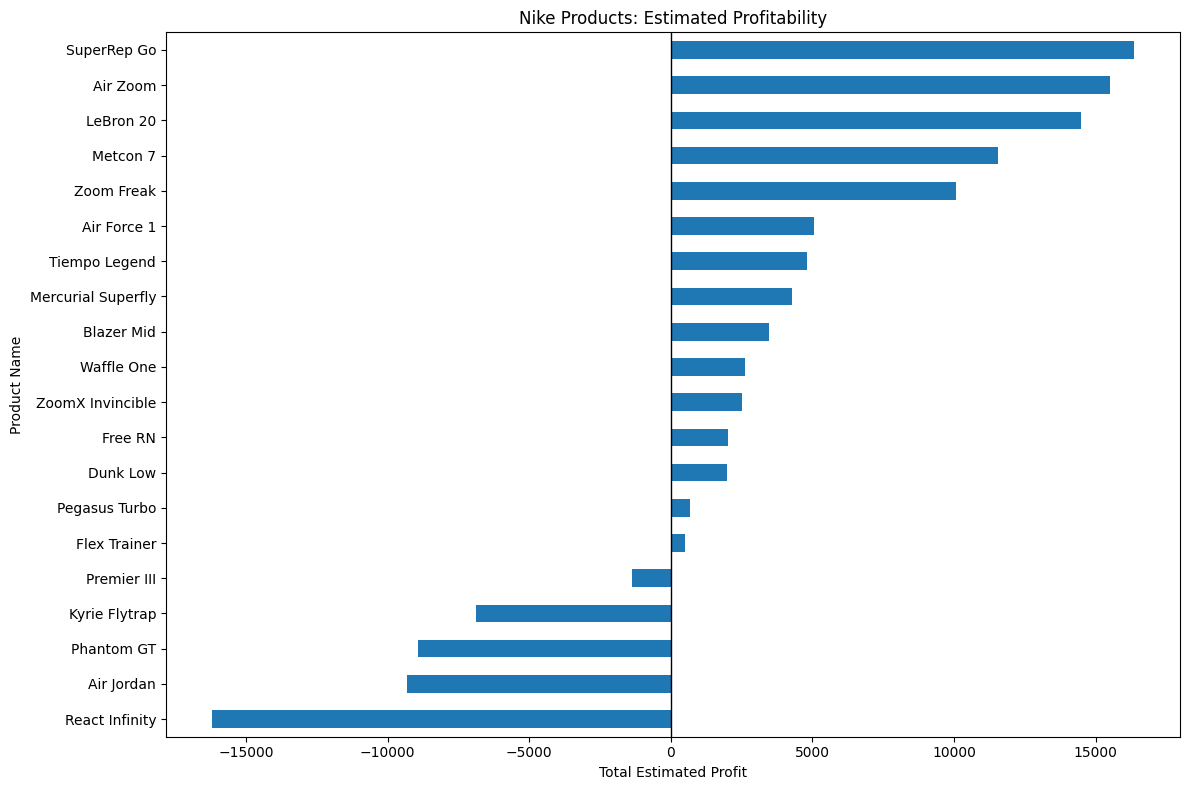

In [274]:
# Product profitability chart

plt.figure(figsize=(12, 8))

product_analysis["Total_Estimated_Profit"].sort_values().plot(
    kind="barh"
)

plt.title("Nike Products: Estimated Profitability")
plt.xlabel("Total Estimated Profit")
plt.ylabel("Product Name")

plt.axvline(x=0, color="black", linewidth=1)

plt.tight_layout()
plt.show()

In [275]:
# Analyse estimated profit by region

region_analysis = profit_data.groupby("Region").agg(
    Total_Orders=("Order_ID", "count"),
    Total_Revenue=("Revenue", "sum"),
    Total_Estimated_Profit=("Estimated_Profit", "sum"),
    Average_Profit=("Estimated_Profit", "mean")
).round(2)

# Sort regions by estimated profit

region_analysis = region_analysis.sort_values(
    by="Total_Estimated_Profit",
    ascending=False
)

display(region_analysis)

,Total_Orders,Total_Revenue,Total_Estimated_Profit,Average_Profit
Region,,,,
Kolkata,21,178788.26,27644.29,1316.39
Pune,15,123497.86,21676.67,1445.11
Delhi,17,125131.77,8054.47,473.79
Hyderabad,4,32436.47,5933.31,1483.33
Mumbai,21,106766.67,4833.08,230.15
Hyd,1,10224.99,4438.02,4438.02
hyderbad,12,97520.33,-2804.53,-233.71
bengaluru,9,61644.62,-6210.54,-690.06
Bangalore,10,65322.19,-10295.56,-1029.56


In [276]:
# Create a clean region column

profit_data["Region_Clean"] = profit_data["Region"].str.strip()

profit_data["Region_Clean"] = profit_data["Region_Clean"].replace({
    "Hyd": "Hyderabad",
    "hyderbad": "Hyderabad",
    "Bangalore": "Bengaluru",
    "bengaluru": "Bengaluru"
})

# Analyse profit using the cleaned region names

region_analysis_clean = profit_data.groupby("Region_Clean").agg(
    Total_Orders=("Order_ID", "count"),
    Total_Revenue=("Revenue", "sum"),
    Total_Estimated_Profit=("Estimated_Profit", "sum"),
    Average_Profit=("Estimated_Profit", "mean")
).round(2)

region_analysis_clean = region_analysis_clean.sort_values(
    by="Total_Estimated_Profit",
    ascending=False
)

display(region_analysis_clean)

,Total_Orders,Total_Revenue,Total_Estimated_Profit,Average_Profit
Region_Clean,,,,
Kolkata,21,178788.26,27644.29,1316.39
Pune,15,123497.86,21676.67,1445.11
Delhi,17,125131.77,8054.47,473.79
Hyderabad,17,140181.79,7566.80,445.11
Mumbai,21,106766.67,4833.08,230.15
Bengaluru,19,126966.81,-16506.09,-868.74


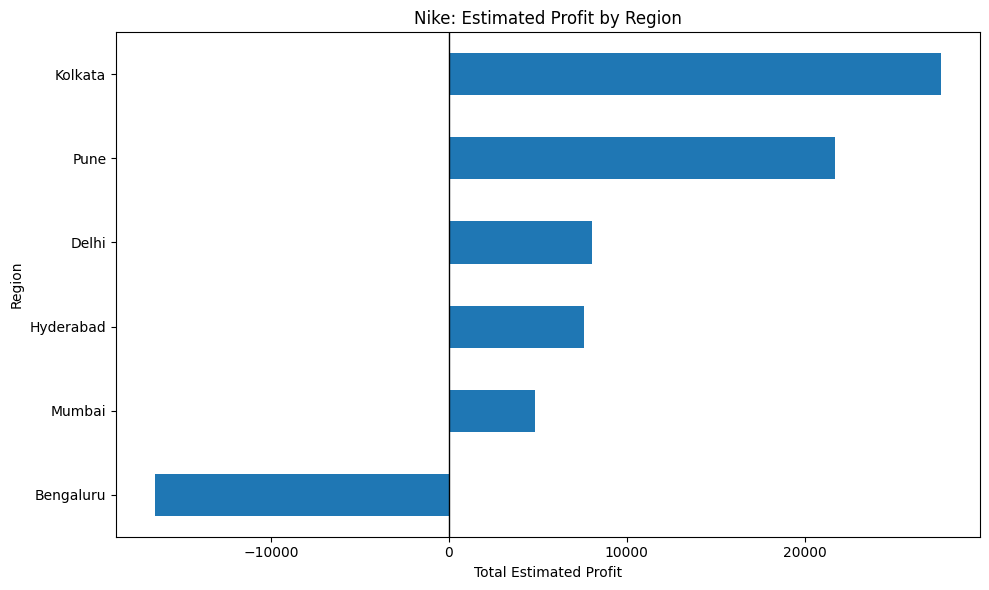

In [277]:
# Regional profitability chart

plt.figure(figsize=(10, 6))

region_analysis_clean["Total_Estimated_Profit"].sort_values().plot(
    kind="barh"
)

plt.title("Nike: Estimated Profit by Region")
plt.xlabel("Total Estimated Profit")
plt.ylabel("Region")

plt.axvline(x=0, color="black", linewidth=1)

plt.tight_layout()
plt.show()

In [278]:
# Analyse estimated profit by sales channel

channel_analysis = profit_data.groupby("Sales_Channel").agg(
    Total_Orders=("Order_ID", "count"),
    Total_Revenue=("Revenue", "sum"),
    Total_Estimated_Profit=("Estimated_Profit", "sum"),
    Average_Profit=("Estimated_Profit", "mean")
).round(2)

channel_analysis = channel_analysis.sort_values(
    by="Total_Estimated_Profit",
    ascending=False
)

display(channel_analysis)

,Total_Orders,Total_Revenue,Total_Estimated_Profit,Average_Profit
Sales_Channel,,,,
Retail,57,386968.67,47608.26,835.23
Online,53,414364.49,5660.96,106.81


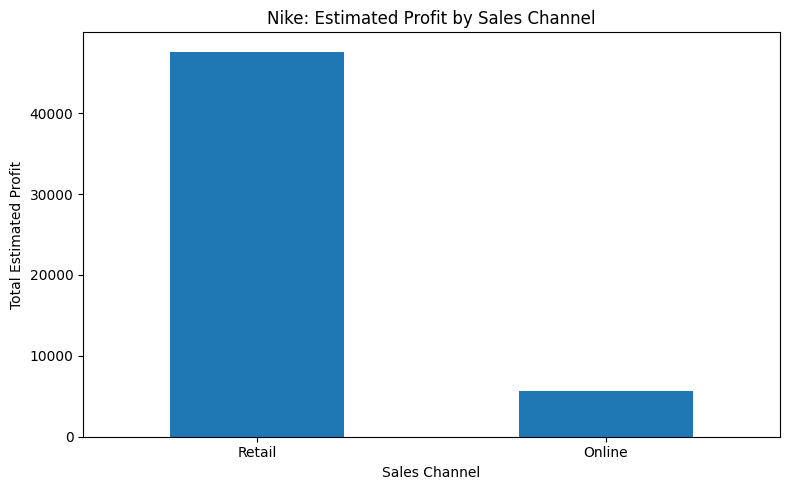

In [279]:
# Sales channel profitability chart

plt.figure(figsize=(8, 5))

channel_analysis["Total_Estimated_Profit"].plot(
    kind="bar"
)

plt.title("Nike: Estimated Profit by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Total Estimated Profit")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [280]:
# Analyse discounts and estimated profit

discount_analysis = profit_data.groupby("Discount_Applied").agg(
    Total_Orders=("Order_ID", "count"),
    Average_Profit=("Estimated_Profit", "mean"),
    Total_Estimated_Profit=("Estimated_Profit", "sum")
).round(2)

display(discount_analysis)

,Total_Orders,Average_Profit,Total_Estimated_Profit
Discount_Applied,,,
0.01,3,12313.11,36939.33
0.02,1,3404.04,3404.04
0.04,1,4391.55,4391.55
0.05,1,2796.97,2796.97
0.06,1,4966.63,4966.63
...,...,...,...
0.92,1,-10602.49,-10602.49
0.93,1,-15787.90,-15787.90
0.94,1,-7912.53,-7912.53


In [281]:
# Group discounts into categories

profit_data["Discount_Category"] = pd.cut(
    profit_data["Discount_Applied"],
    bins=[-0.001, 0.25, 0.50, 0.75, 1.0],
    labels=["Low", "Medium", "High", "Very High"]
)

# Analyse profitability by discount category

discount_category_analysis = profit_data.groupby(
    "Discount_Category",
    observed=False
).agg(
    Total_Orders=("Order_ID", "count"),
    Average_Profit=("Estimated_Profit", "mean"),
    Total_Estimated_Profit=("Estimated_Profit", "sum")
).round(2)

display(discount_category_analysis)

,Total_Orders,Average_Profit,Total_Estimated_Profit
Discount_Category,,,
Low,32,5324.38,170380.27
Medium,31,1697.57,52624.63
High,25,-1582.47,-39561.72
Very High,22,-5917.00,-130173.97


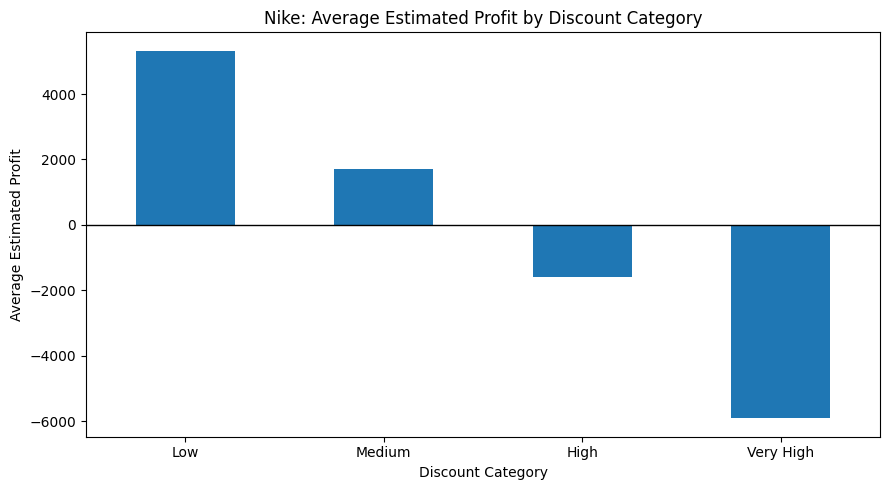

In [282]:
# Discount category profitability chart

plt.figure(figsize=(9, 5))

discount_category_analysis["Average_Profit"].plot(
    kind="bar"
)

plt.title("Nike: Average Estimated Profit by Discount Category")
plt.xlabel("Discount Category")
plt.ylabel("Average Estimated Profit")

plt.axhline(y=0, color="black", linewidth=1)

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [283]:
# Analyse profitability by product line

product_line_analysis = profit_data.groupby("Product_Line").agg(
    Total_Orders=("Order_ID", "count"),
    Total_Revenue=("Revenue", "sum"),
    Total_Estimated_Profit=("Estimated_Profit", "sum"),
    Average_Profit=("Estimated_Profit", "mean")
).round(2)

product_line_analysis = product_line_analysis.sort_values(
    by="Total_Estimated_Profit",
    ascending=False
)

display(product_line_analysis)

,Total_Orders,Total_Revenue,Total_Estimated_Profit,Average_Profit
Product_Line,,,,
Training,29,211229.29,30924.83,1066.37
Lifestyle,18,179814.05,13157.94,731.00
Basketball,25,168381.68,8383.47,335.34
Running,14,94609.75,2010.54,143.61
Soccer,24,147298.39,-1207.56,-50.31


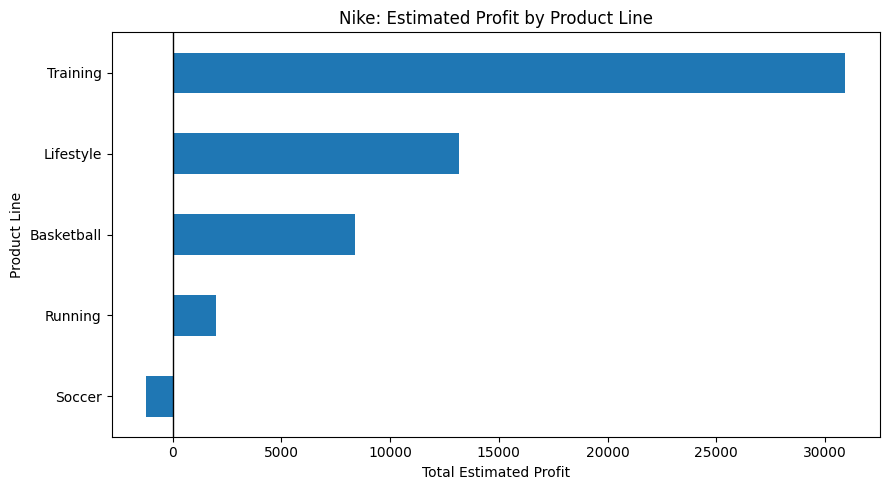

In [284]:
# Product line profitability chart

plt.figure(figsize=(9, 5))

product_line_analysis["Total_Estimated_Profit"].sort_values().plot(
    kind="barh"
)

plt.title("Nike: Estimated Profit by Product Line")
plt.xlabel("Total Estimated Profit")
plt.ylabel("Product Line")

plt.axvline(x=0, color="black", linewidth=1)

plt.tight_layout()
plt.show()

In [285]:
# Final financial verification

print("FINAL FINANCIAL SUMMARY")
print("-----------------------")

print("Total Revenue:",
      round(profit_data["Revenue"].sum(), 2))

print("Total Production Cost:",
      round(profit_data["Estimated_Production_Cost"].sum(), 2))

print("Total Transportation Cost:",
      round(profit_data["Estimated_Transportation_Cost"].sum(), 2))

print("Total Online Shipment Cost:",
      round(profit_data["Online_Shipment"].sum(), 2))

print("Total Estimated Profit:",
      round(profit_data["Estimated_Profit"].sum(), 2))

FINAL FINANCIAL SUMMARY
-----------------------
Total Revenue: 801333.16
Total Production Cost: 697334.94
Total Transportation Cost: 46489.0
Total Online Shipment Cost: 4240.0
Total Estimated Profit: 53269.22
